# HW3 — Groundwater Hydrology


## Groundwater Concepts


In [1]:
# import packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Soil and Aquifer Properties


### Soil Properties


In [2]:
# define volumetric fractions of water, soil, and pore space
V_water = 0.22
V_soil = 0.58
V_air = 0.31
V_total = V_water + V_soil + V_air

# calculate soil porosity
n = 1 - V_soil/V_total

# calculate soil water content
theta = V_water/V_total

# calculate saturation
theta_star = theta/n

# print statements
print(f'Soil porosity:  {n:.2f}')
print(f'Soil water content:  {theta:.2f}')
print(f'Saturation:  {theta_star:.2f}')

Soil porosity:  0.48
Soil water content:  0.20
Saturation:  0.42


### Aquifer Properties


## ParFlow Sandtank Exploration


## Darcy's Law and the Dupuit Approximation


### Groundwater Flow and Conservation


### Unconfined Aquifer Flow


### Dupuit Approximation: Numerical Example


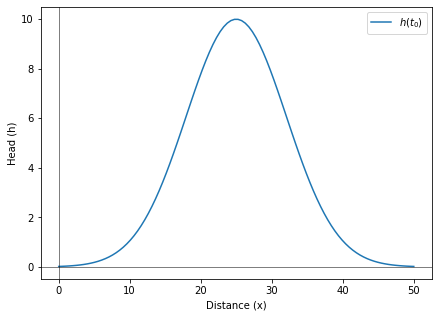

In [3]:
# example - some unrealistic initial conditions
# assume that R_I=0, we are only looking in the x-direction, and K_h=S_y=1
# the head on the left and right are approx 0

# initial distribution of water (bell curve)
x = np.linspace(0,50,100)
h_0 = 10*np.exp(-((x-25)/10)**2)

# see what this looks like
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(x, h_0, label=r'$h(t_0)$')
ax.set_xlabel("Distance (x)")
ax.set_ylabel("Head (h)")
ax.axhline(y=0,color='k',linewidth=0.5)
ax.axvline(x=0,color='k',linewidth=0.5)
ax.legend()

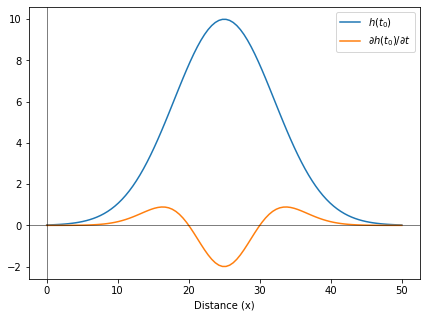

In [4]:
# set values of hydraulic conductivity (K_h) and specific yield (S_y)
K_h = 1.0
S_y = 1.0

# now let's approximate dh/dt using the second derivative of h^2
d2h2_dt2 = (4/25)*np.exp(-(1/50)*(x-25)**2)*(x**2-50*x+600)
# found using wolframalpha.com

# complete the left-hand side to calculate dh/dt
dh_dt = (K_h/(2*S_y))*d2h2_dt2

# see what this looks like
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(x, h_0, label=r'$h(t_0)$')
ax.plot(x, dh_dt, label=r'$\partial h(t_0) / \partial t$')
ax.axhline(y=0,color='k',linewidth=0.5)
ax.axvline(x=0,color='k',linewidth=0.5)
ax.set_xlabel("Distance (x)")
ax.legend()

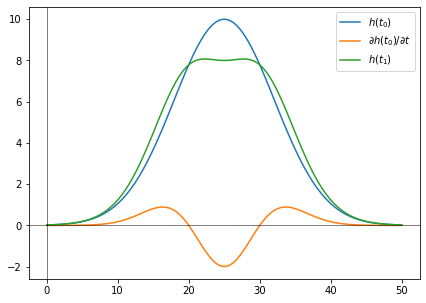

In [5]:
# lastly, find h at the next timestep by adding the approximation of dh/dt
h_1 = h_0 + dh_dt

# see what this looks like
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(x, h_0, label=r'$h(t_0)$')
ax.plot(x, dh_dt, label=r'$\partial h(t_0) / \partial t$')
ax.plot(x, h_1, label=r'$h(t_1)$')
ax.axhline(y=0,color='k',linewidth=0.5)
ax.axvline(x=0,color='k',linewidth=0.5)
ax.legend()

### Steady-State Aquifer Drainage


### Steady-State Water Table Example


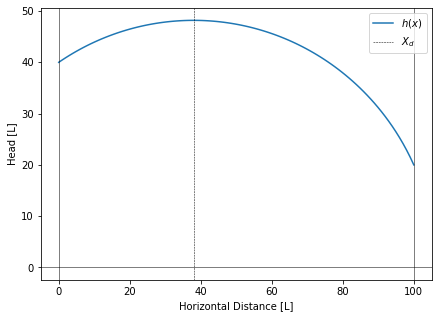

In [6]:
# set parameters: h_0 (left end), h_X (right end), X (spacing between streams), R_I, and K_h
h_0 = 40.0
h_X = 20.0
X = 100.0
R_I = 1.0
K_h = 2.0

# create mesh based on length between streams
x = np.linspace(0,X,100)

# define function to calculate h
def h(x):
    return np.sqrt(-(R_I/K_h)*x**2 + x*(((h_X**2 - h_0**2)/X) + (R_I*X/K_h)) + h_0**2)

# define function to calculate X_d and h_max (steady state infiltration)
def ss_infiltration(h_0, h_X, X, R_I, K_h):

    # note that all of these parameters are defined above as global variables
    # but you could change anytime you call the equation

    # calculate X_d (local variables)
    X_d_local = 0.5*X - (K_h*(h_0**2.0 - h_X**2.0))/(2*R_I*X)

    # calculate h_max (a local variable using h defined above, a global function)
    h_max_local = h(X_d_local)

    # return both values
    return X_d_local, h_max_local

# call the function
X_d, h_max = ss_infiltration(h_0, h_X, X, R_I, K_h)

# plot
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(x,h(x),label=r'$h(x)$')
# plot vertical and horizontal lines
ax.axvline(x=0,color='k',linewidth=0.5)
ax.axvline(x=X,color='k',linewidth=0.5)
ax.axvline(x=X_d, color = 'k',linewidth=0.5, linestyle='dashed',label=r'$X_d$')
ax.axhline(y=0, color='k', linewidth=0.5)
ax.set_ylabel('Head [L]')
ax.set_xlabel('Horizontal Distance [L]')
ax.legend(loc='upper right')

## Linear-Reservoir Aquifer Drainage


In [7]:
# metadata
start_date = "2016-04-01"
end_date = "2016-06-15"
headers = ["USGS","site_no","datetime","depth [ft]","approval"]
site_no = "402512074414301"
# near the intersection of Blawenburg Belle Mead Rd. and Skillman Rd

# create url to load data from
url = f'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site_no}&startDT={start_date}&endDT={end_date}&siteStatus=all'
# read in the data and set headers
north_well = pd.read_csv(url, sep='\t', skiprows=29,header=None)
north_well.columns = headers
# Lat 40°25'12", long 74°41'43"

# set depth using altitude of well
# Land-surface datum is 110 ft above National Geodetic Vertical Datum of 1929
north_well['WT'] = 110 - north_well['depth [ft]']

# get rain from daymet using same start and end date as above
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start="+start_date+"&end="+end_date+"&format=csv"

# read in the data
weather = pd.read_csv(url, skiprows=6)
#print(weather.head())

# add the precip column from the weather dataframe to the north_well dataframe
# (keeping everything in one dataframe makes things easier down the road)
north_well['rain'] = weather['prcp (mm/day)']
north_well.head()

,USGS,site_no,datetime,depth [ft],approval,WT,rain
0,USGS,402512074414301,2016-04-01,14.81,A,95.19,2.59
1,USGS,402512074414301,2016-04-02,14.87,A,95.13,5.27
2,USGS,402512074414301,2016-04-03,15.26,A,94.74,0.00
3,USGS,402512074414301,2016-04-04,15.50,A,94.50,3.28
4,USGS,402512074414301,2016-04-05,15.94,A,94.06,0.00


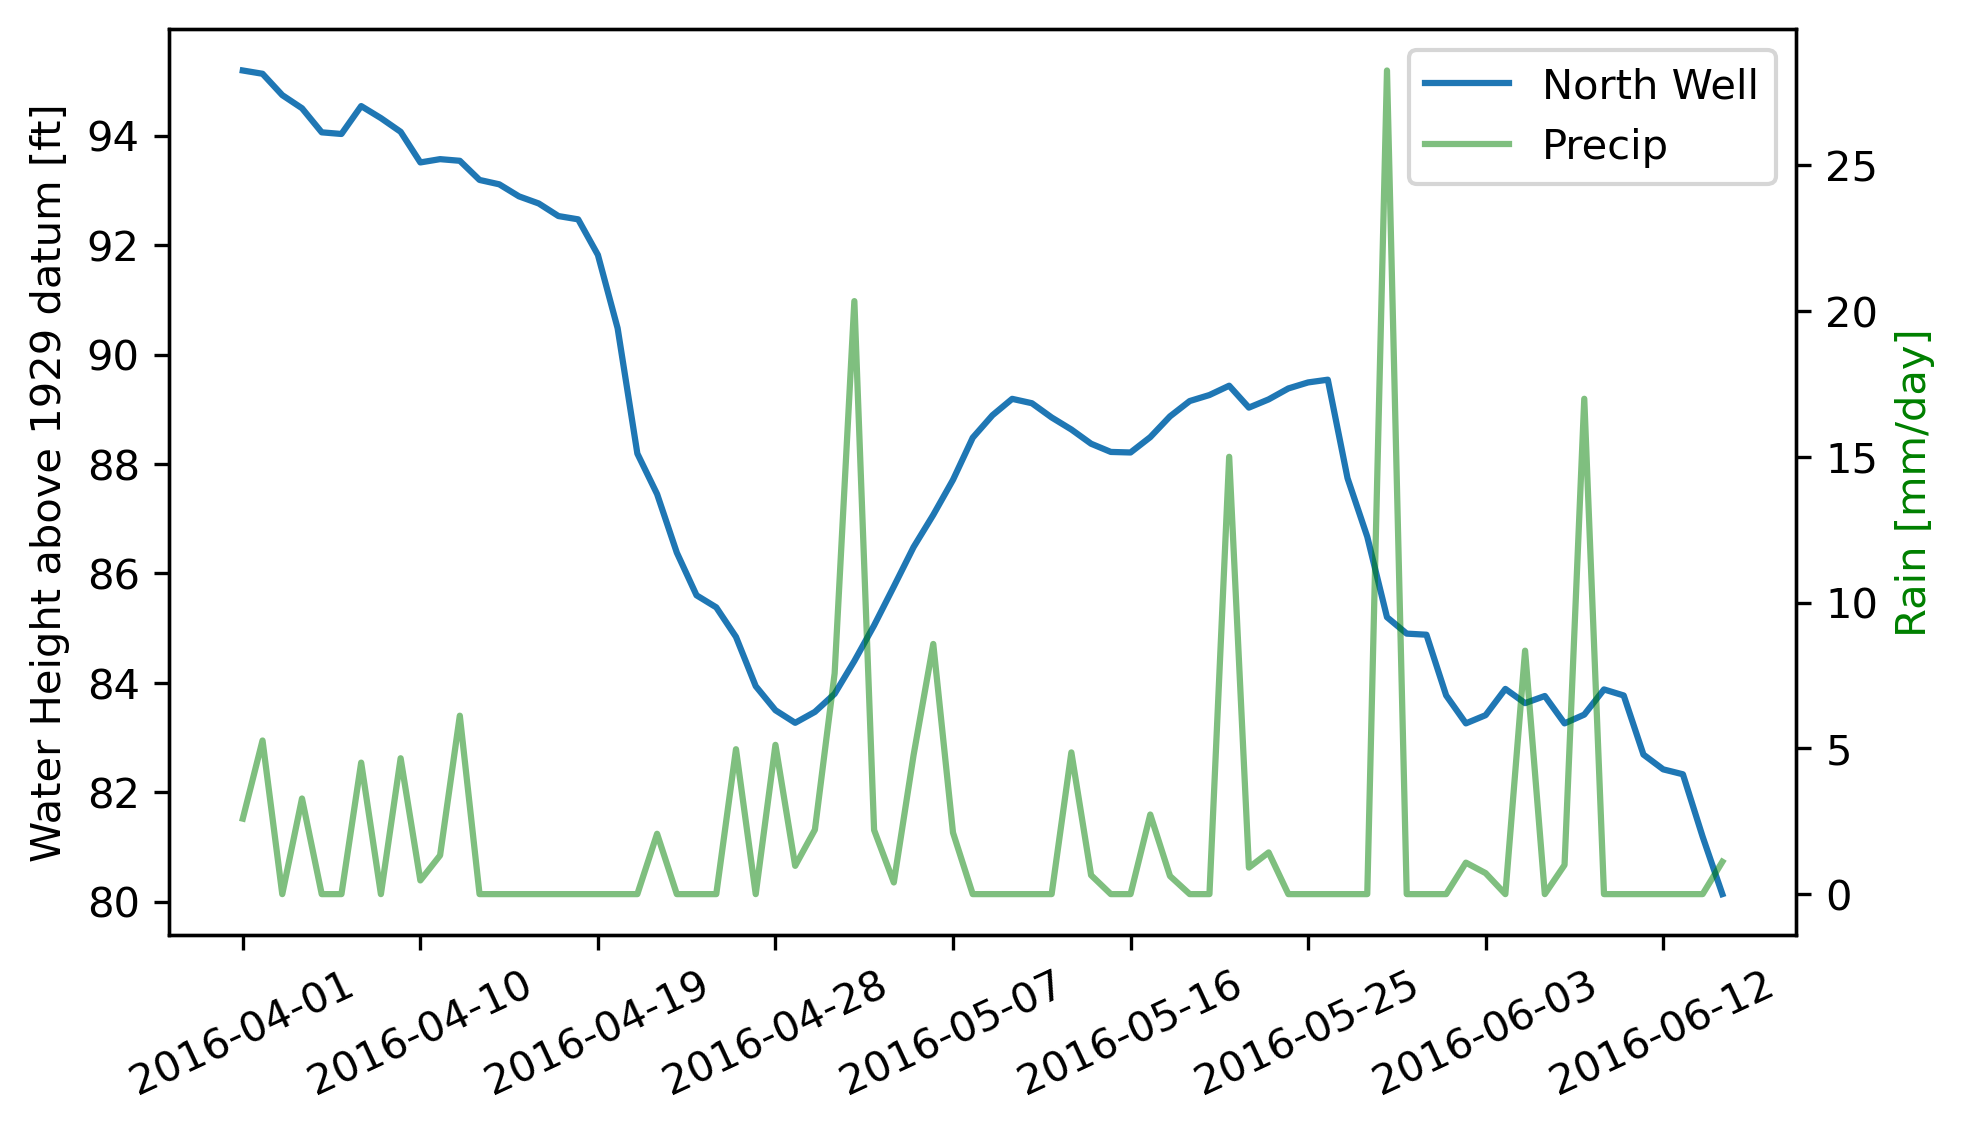

In [8]:
# plot data
fig, ax = plt.subplots(figsize=(7,4), dpi=300)
well_series = ax.plot(north_well['datetime'], north_well['WT'], label = 'North Well')
ax.set_ylabel('Water Height above 1929 datum [ft]')

# twin axis
ax2 = ax.twinx()
rain_series = ax2.plot(north_well['datetime'], north_well['rain'], alpha=0.5, color='green',label = 'Precip')
ax2.set_ylabel('Rain [mm/day]', color='green')

# maxe xticks look nicer
ax.set_xticks(north_well['datetime'][::len(north_well['datetime']) // 8])
ax.tick_params(axis='x', labelrotation=25)

# make legends show up in one box for twin axis
all_series = well_series + rain_series
labels = [s.get_label() for s in all_series]
ax.legend(all_series, labels)

## Homework Analysis


### 1. Aquifer Heterogeneity and Anisotropy


`<Q1.1 Heterogeneity, unlike homogeneity, is the variations in aquifer properties, such as hydraulic conductivity, porosity, or storativity, from place to place within the aquifer. So, properities depend on the location in heterogenous aquifer.>` 

`<Anisotropy is another term that means the directional differences in aquifer properties. One example is the difference in hydraulic conductivity in horizontal direction and vertical direction. While dupuit approximation solely focuses on the horizontal movement, anisotropy shows some difference of properties based on the direction, not specific like location.>`

`<Q1.2 Yes, I believe it is possible for the groundwater to be anisotropic and yet homogenous. If the aquifer has uniform material everywhere, for example some type of soil, it is considered as the homogenous. However, the flow properties can differ with direction due to subsurface sediment layering and other reasons. So, it can be anisotropic. Yes, groundwater flow can be anisotropic yet homogeneous. Homogeneity considers more about 3D spatial location (x,y,z), while anisotropy concerns about simply the directional variation (horizontal vs vertical vs z-direction).>`

### 2. ParFlow Sandtank Observations


`<Q2.1 On ParFlow Sandtank, changing particle size affects the variable K, the hydraulic conductivity, of Dracy's law that calculates the flow of water within the subsurface. For example, larger particles (gravel) have higher hydraulic conductivity, aloowing water to move faster. Smaller particles (like clay) slow water flow due to its lower hydraulic conducitivity. The flow generally becomes gradually slower changing the property one by one from gravel, soil to clay. On Sandtank, it is visible in how fast the water level inside the wells change depending on the material properties>`

`<Q2.2>`


`<A. With default soils (Gravel-Loam-Sand-Clay), water table rises and drops quickly back as it is right now at the gravel with high hydraulic conductivity. Pollutant injected alongside water from Well A spreads in both horizontal and vertical direction but do not transfer into other soils as it seems to be domainated by the loam. It also does not penetrate uniformly into all soils because the subsurface is heterogeneous rather than perfectly layered homogenous.>`

`<B. I believe due to changing Soil 1 to be clay, we now have two clay soils. So, even though the diagram is showing loam around the well, there is more presence of clay and it slows down the movement, limiting the pollutant released to move mainly horizontally, with barely any vertical movement. Horizontal water table / head movement seemed a bit slower compared to having Soil 1 as gravel.>`

`<C. If Soil 4 is changed to gravel, new downward permeability path is created so pollutant is spreading mostly downward, widely, resembling plant's wide root system. Vertical movement starts being active because of enhanced conductivity>`

### 3. Groundwater Recession Modeling


In [9]:
# loading in data - don't need to change anything in this cell (but make sure you understand it)
# but feel free to uncomment print statements to check out the data

# metadata, url, and loading data (same as above)
start_date = "2016-04-18"
end_date = "2016-04-24"
headers = ["USGS","site_no","datetime","depth [ft]","approval"]
site_no = "402512074414301"
url = f'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site_no}&startDT={start_date}&endDT={end_date}&siteStatus=all'
north_well = pd.read_csv(url, sep='\t', skiprows=29,header=None)
north_well.columns = headers
# Lat 40°25'12", long 74°41'43"
#print(url)

# set depth using altitude of well
# Land-surface datum is 110 ft above National Geodetic Vertical Datum of 1929
north_well['WT'] = 110 - north_well['depth [ft]']

# get rain from daymet using same start and end date as above, but you do not need to use it
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start="+start_date+"&end="+end_date+"&format=csv"
weather = pd.read_csv(url, skiprows=6)

# add the precip column from the weather dataframe to the north_well dataframe
# (keeping everything in one dataframe makes things easier down the road)
north_well['rain'] = weather['prcp (mm/day)']
north_well#.head()

,USGS,site_no,datetime,depth [ft],approval,WT,rain
0,USGS,402512074414301,2016-04-18,17.53,A,92.47,0.00
1,USGS,402512074414301,2016-04-19,18.18,A,91.82,0.00
2,USGS,402512074414301,2016-04-20,19.52,A,90.48,0.00
3,USGS,402512074414301,2016-04-21,21.81,A,88.19,0.00
4,USGS,402512074414301,2016-04-22,22.55,A,87.45,2.07
5,USGS,402512074414301,2016-04-23,23.62,A,86.38,0.00
6,USGS,402512074414301,2016-04-24,24.40,A,85.60,0.00


7


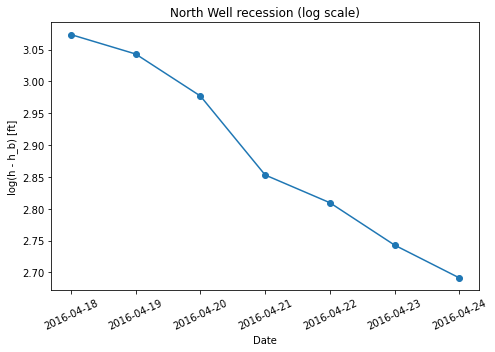

Calculated c (inverse of residence time): 0.0684 per day


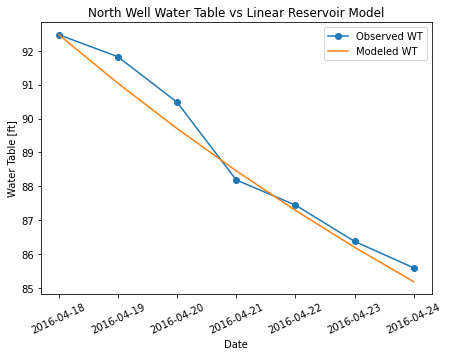

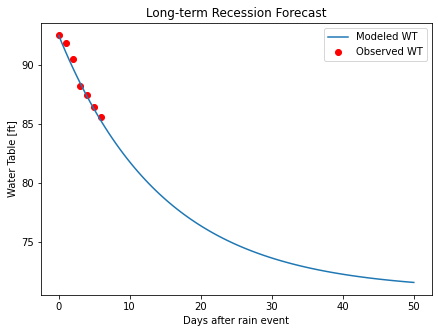

In [10]:
# define h_b as the minimum water table head from 2014 - 2018 [ft]
h_b = 70.85

# get the number of days in dataframe
no_of_days = len(north_well.index)
print(no_of_days)

### your code below here ###

# STEP 1: Use h_b to make a column h - h_b
# and convert the column of north_well head to logarithmic units and plot

north_well['h_minus_hb'] = north_well['WT'] - h_b

plt.figure(figsize=(7,5))
plt.plot(pd.to_datetime(north_well['datetime']), np.log(north_well['h_minus_hb']), marker='o')
plt.ylabel('log(h - h_b) [ft]')
plt.xlabel('Date')
plt.title('North Well recession (log scale)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()



#So, here I plotted the actual drainage graph using the observed data. Doing it with np.log can clearly show the decrease trend. 
#Now Step 2 is having a best fit line for my first plot and finding the slope, which is c. 

# STEP 2: Calculate c and print the value with units
# be sure to define h_0 from the dataframe
# and make sure to print the value of c

t_days = np.arange(len(north_well))  # 0 to 6, so total 7 days
ln_h_diff = np.log(north_well['h_minus_hb']) #using this to make it a linearized straight line

#Finding slope of the best fit line as python is capable for doing it through np.polyfit automatically
slope, intercept = np.polyfit(t_days, ln_h_diff, 1)
c = -slope  # positive
print(f'Calculated c (inverse of residence time): {c:.4f} per day')


# STEP 3: Create a function to model this decrease.
# A time axis has been created for you

# create time axis in days
h_0 = north_well['WT'].iloc[0]  # 110-17.53 ft 's one as the initial for our model.
h_model = h_b + (h_0 - h_b) * np.exp(-c*t_days)

#Now I am plugging the c value back to the formula given which gives me the smooth exponential decay. 

# STEP 4: Plot your model over the original data (not in logspace), and comment on any differences

plt.figure(figsize=(7,5))
plt.plot(pd.to_datetime(north_well['datetime']), north_well['WT'], marker='o', label='Observed WT')
plt.plot(pd.to_datetime(north_well['datetime']), h_model, label='Modeled WT')
plt.xlabel('Date')
plt.ylabel('Water Table [ft]')
plt.title('North Well Water Table vs Linear Reservoir Model')
plt.legend()
plt.xticks(rotation=25)
plt.show()

#While the general trend is matching, there seems to be certain small differences that the model cannot capture. 


# STEP 5: Plot the model for a long time (say, 7 weeks) to examine the drainage behavior as if no rain had fallen
# plot it on top of the original data (you will need to use two different time axes)
# for this plot, you do not need to have the dates on the x-axis, number of days after rain event is fine

# create new time axis in days. So, here I am doing for 50 days using 100 points for smoothness. 
t_long = np.linspace(0,50,100)

h_long = h_b + (h_0 - h_b) * np.exp(-c*t_long)

plt.figure(figsize=(7,5))
plt.plot(t_long, h_long, label='Modeled WT')
plt.scatter(t_days, north_well['WT'], color='red', label='Observed WT')
plt.xlabel('Days after rain event')
plt.ylabel('Water Table [ft]')
plt.title('Long-term Recession Forecast')
plt.legend()
plt.show()


`<Q3.3 The linear reservoir model is capturing the overall trend of the exponential decline of the water table after the rain event. However, the observed data fluctuates slightly above and below the model's best fit line on some days. These differences can occur because of heterogeneity in soil properities, or model not accounting for some short-term rainfall (2.07 mm on Apr 22) that is happening. Overall, I think model can provide a reasonable and accurate first approximation of the subsurface behavior.>`

### 4. Two-Reservoir Streamflow Model


In [11]:
## LEAVE THIS CELL AS IT IS (but feel free to uncomment print statements)

## Get data
start_date = "2020-02-28"
end_date = "2020-03-02"

## flow from StonyBrook
url = "https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&period=&begin_date="+start_date+"&end_date="+end_date
StonyBrook = pd.read_csv(url, skiprows=28, sep='\t', header=None)
StonyBrook.columns = ["agency_cd","site_no","datetime","tz_cd","flow_cfs","194689_00060_cd"]
#print(StonyBrook)
print(url)

## put flow into inches/day
# conversions
area = 44.5*2.788e7 # square feet
inches_per_foot = 12 # inches
seconds_per_day = 60*60*24 # seconds
inches_per_mm = 0.0393701 # inches

# create new inches_per_day column
StonyBrook['flow_in_per_day'] = StonyBrook['flow_cfs']*inches_per_foot*seconds_per_day/area

## most recent available WT data is at 96.5 feet (this is h_0)
#StonyBrook

https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&period=&begin_date=2020-02-28&end_date=2020-03-02


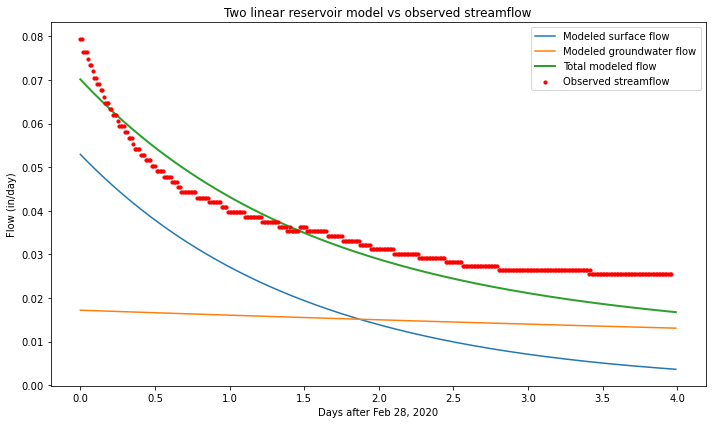

In [12]:
## define numerical parameters for the model

# create dt in 15 minute intervals with units of days
dt = 15*(1/60)*(1/24) #days = 15 minutes

### how many days between 02/28/2020 - 03/02/2020? One day every 4 years that give computational hydrologists a small headache...
# n_days = FILL IN THIS VALUE!!!!!
###

# number of timesteps
n_days = 4
n_tsteps = int(n_days / dt)

# set S_y
# experiment with this value. #I raised it to 0.15
S_Y = 0.01

# set T_star
# experiment with this value
T_star = 1.5

# set h_0, from recent WT data
h_0 = 96 * inches_per_foot



### your code below here ###

# STEP 1: define c value from above, and initialize arrays

t = np.arange(n_tsteps) * dt   # time axis in days

Q_gw   = np.zeros(n_tsteps)
Q_surf = np.zeros(n_tsteps)
V_surf = np.zeros(n_tsteps)    #decided to use V_surf for Euler linear resoivor like I did in HW1



# STEP 2: set any initial conditions by putting the first value in each array

h_0_ft  = 96.0                          # well head [ft], given in problem
Q_gw[0] = c * S_Y * (h_0_ft - h_b)     # initial GW flow using Q3's c
V_surf[0] = StonyBrook['flow_in_per_day'].iloc[0]  # starting surface storage at first observed flow


# STEP 3: use a loop to fill the arrays

for i in range(1, n_tsteps):
    # groundwater: analytical (from Q3)
    Q_gw[i] = c * S_Y * (h_0_ft - h_b) * np.exp(-c * t[i])

    # surface: Euler integration. same as my previous HW, just no rain input
    Q_surf[i-1] = V_surf[i-1] / T_star
    V_surf[i]   = V_surf[i-1] - Q_surf[i-1] * dt
    if V_surf[i] < 0:
        V_surf[i] = 0

# filling last surface flow value
Q_surf[-1] = V_surf[-1] / T_star

# total flow that includes surface and gw
Q_total = Q_gw + Q_surf


#STEP 4: plot

fig, ax = plt.subplots(figsize=(10, 6))

# observed: using days since start for x-axis (3)
t_obs = np.arange(len(StonyBrook)) * dt  # same dt, just for observed points

ax.scatter(t_obs, StonyBrook['flow_in_per_day'], color='red', s=10, label='Observed streamflow', zorder=5)
ax.plot(t, Q_surf,  label='Modeled surface flow')
ax.plot(t, Q_gw,    label='Modeled groundwater flow')
ax.plot(t, Q_total, label='Total modeled flow', linewidth=2)
ax.set_xlabel('Days after Feb 28, 2020')
ax.set_ylabel('Flow (in/day)')
ax.set_title('Two linear reservoir model vs observed streamflow')
ax.legend()
plt.tight_layout()
plt.show()


`Q4 For the groundwater reservoir, c, h_0, and h_b were kept the same as Q3. The only tuned parameter was S_Y, which the given starting value of 0.0005 made GW flow essentially zero, so I experimented with larger values. I ended up choosing S_Y = 0.01 and T_star = 1.5 as the best, closest values that approximates the observed streamflow. For the surface reservoir, T_star = 1.5 days was chosen and it drains slower than the given 0.8. The calculation was simply the Euler numerical method that I used in HW1 for linear resoirvoir model.` 

`Some observations I have from the result: The total modeled flow closely matches and overlaps a bit with the observed streamflow, which is the ultimate goal. The modeled surface flow sits just below the total, meaning surface runoff is the dominant contributor in this period of post-storm window. Groundwater flow is small (around 0.02 in/day) and appears nearly flat = this makes sense because its timescale is 1/c = about 15 days, so over just 3 days we are barely seeing it decay at all. If the plot were extended to 50 days like Q3, groundwater might have become the dominant signal as surface flow disappears completely.`



### Collaboration and AI-Use Disclosure


`I used AI for np.polyfit and generally plotting the best fit line, and solving certain bugs I got for Q4's timing.`